# Experimentos pendientes: potencial, diseños detectores y lema de información

Cuatro piezas del plan del 22 de octubre, cada una con su número regenerado y su `assert`. Convención fija: conteos exactos, soft clearing, $q=1/2$, $u=1$; tres regímenes, **estático**, **dinámico binario** y **dinámico aumentado**; aquí todo es dinámico aumentado, laminar o general.

Cómo leerlo: 1) el paso de partir del potencial de Francisco; 2) diseños detectores frente al óptimo laminar; 3) el lema $\mathbb E[\text{despejados}]\le\log_2 K+1$ comprobado en la malla; 4) el barrido de la nota "individuales". Nada escrito a mano.

In [1]:
import os, sys, time
sys.path.insert(0, os.path.dirname(os.path.dirname(os.path.abspath(''))))
from fractions import Fraction as F
from math import comb, log2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AZUL, GRIS, AMBAR, TINTA = '#2563eb', '#6b7280', '#d97706', '#374151'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.25, 'grid.linewidth': 0.5, 'font.size': 10})

## 1. El paso de partir del potencial

Francisco mide el estado con $\phi(m,r)=(m-2r)^2/m$ por átomo ($m$ personas, $r$ infectadas) y suma sobre átomos. Juguete: un átomo de $m=4$ con $r=2$ vale $0$; si una prueba de $k=2$ encuentra $X$ infectados, queda $\phi(2,X)+\phi(2,2-X)$, que vale $0$ si $X=1$ y $4$ si $X\in\{0,2\}$. Con $X$ hipergeométrica, el salto esperado es $4\cdot\tfrac13=\tfrac43$.

Afirmación (V2 del acta, derivación IA): para todo $m\le12$, $r$, $k$, $\mathbb E[\Delta]=4r(m-r)/(m(m-1))\le2$, y una prueba virgen sube el potencial exactamente $1$.

In [2]:
def phi(m, r):
    return F((m - 2 * r) ** 2, m) if m else F(0)

def split_gain(m, r, k):
    """E[phi(k,X) + phi(m-k, r-X) - phi(m,r)], X ~ Hypergeometric(m, r, k), exact."""
    total = F(0)
    for x in range(max(0, k - (m - r)), min(k, r) + 1):
        p = F(comb(r, x) * comb(m - r, k - x), comb(m, k))
        total += p * (phi(k, x) + phi(m - k, r - x) - phi(m, r))
    return total

rows = []
for m in range(2, 13):
    for r in range(m + 1):
        for k in range(1, m):
            gain = split_gain(m, r, k)
            assert gain == F(4 * r * (m - r), m * (m - 1)) and gain <= 2, (m, r, k, gain)
            rows.append(dict(m=m, r=r, k=k, gain=float(gain)))
v2 = pd.DataFrame(rows)

virgin = {M: sum(F(comb(M, R), 2 ** M) * phi(M, R) for R in range(M + 1)) for M in range(1, 17)}
assert all(v == 1 for v in virgin.values())
print(f'{len(v2)} tripletas (m,r,k) con m<=12: identidad exacta y cota 2 en todas; '
      f'maximo {v2.gain.max():.4f} en m=2, r=1; prueba virgen = 1 para M=1..16')

638 tripletas (m,r,k) con m<=12: identidad exacta y cota 2 en todas; maximo 2.0000 en m=2, r=1; prueba virgen = 1 para M=1..16


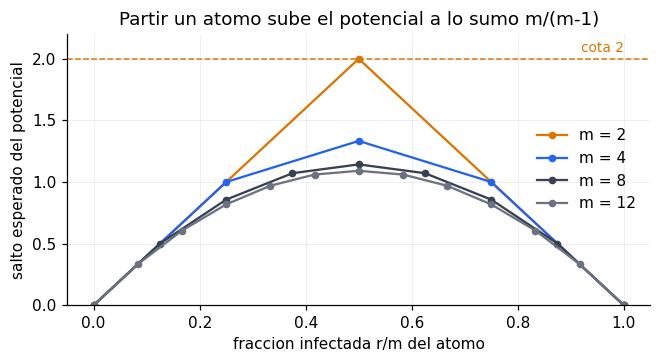

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for m, color in [(2, AMBAR), (4, AZUL), (8, TINTA), (12, GRIS)]:
    sub = v2[(v2.m == m) & (v2.k == 1)]
    ax.plot(sub.r / m, sub.gain, 'o-', ms=4, color=color, label=f'm = {m}')
ax.axhline(2, color=AMBAR, ls='--', lw=1)
ax.text(1.0, 2.03, 'cota 2', ha='right', va='bottom', color=AMBAR, fontsize=9)
ax.set(xlabel='fraccion infectada r/m del atomo', ylabel='salto esperado del potencial',
       title='Partir un atomo sube el potencial a lo sumo m/(m-1)', ylim=(0, 2.2))
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

El salto no depende de $k$ y vale a lo sumo $m/(m-1)$, que alcanza $2$ solo en $m=2$ y tiende a $1$. Con una prueba virgen que sube $1$ y un split que sube $\le2$, el telescopio da $V^*_{lam}\le 2B$ si el potencial domina la utilidad.

Para discutir: ¿el potencial domina la utilidad exactamente porque los despejados son los átomos con $r=0$, cada uno aportando $m$?

## 2. Diseños detectores frente al óptimo laminar

Un diseño detector es una matriz 0-1 cuyas filas son pruebas y cuyas firmas de conteos distinguen los $2^n$ perfiles: identifica a todos y acredita $n/2$ sanos en promedio. Juguete: ABC, ABD, ACD identifica a cuatro personas con tres pruebas de tamaño $3$.

Afirmación: cada diseño de la tabla identifica a todos (comprobado sobre los $2^n$ perfiles y por el evaluador exacto), y el óptimo laminar con los mismos $(n,B,G)$ queda por debajo de $n/2$; la razón laminar/general cae al crecer $G$ con $B$ proporcional.

In [4]:
from augmented.experimento_matriz15_laminar import ExactHomogeneousLaminar, matrix15
from augmented.autoresearch_logg.judge import evaluate, static

def pools_of(matrix):
    return [sum(int(bit) << i for i, bit in enumerate(row)) for row in matrix]

def identifies(pools, n):
    z = np.arange(1 << n, dtype=np.uint32)
    sig = np.stack([np.bitwise_count(z & np.uint32(p)) for p in pools], axis=1)
    return len(np.unique(sig, axis=0)) == (1 << n)

def search_design(n, B, G, trials=4000, seed=0):
    """Random 0-1 matrices with row weight <= G; first one whose signatures are all distinct."""
    rng = np.random.default_rng(seed)
    for _ in range(trials):
        rows = []
        for _ in range(B):
            w = rng.integers(1, G + 1)
            rows.append(sum(1 << int(i) for i in rng.choice(n, size=w, replace=False)))
        if identifies(rows, n):
            return rows
    return None

designs = {'n=4 detector ABC/ABD/ACD': (4, 3, pools_of([[1,1,1,0],[1,1,0,1],[1,0,1,1]])),
           'n=8 dos detectores de 4': (8, 3, pools_of([[1,1,1,0]+[0]*4,[1,1,0,1]+[0]*4,[1,0,1,1]+[0]*4,
                                                      [0]*4+[1,1,1,0],[0]*4+[1,1,0,1],[0]*4+[1,0,1,1]]))}
for n in (5, 6, 7, 8):
    for B in range(3, n + 1):
        found = search_design(n, B, n)
        if found:
            designs[f'n={n} busqueda, G libre'] = (n, max(int(p).bit_count() for p in found), found); break
for G in (3, 4):
    for B in range(4, 9):
        found = search_design(8, B, G)
        if found:
            designs[f'n=8 busqueda, G<={G}'] = (8, G, found); break
m15 = pools_of(matrix15())
designs['n=15 Soderberg-Shapiro'] = (15, 7, m15)
designs['n=16 S-S + individual'] = (16, 7, m15 + [1 << 15])

tabla = []
for name, (n, G, pools) in designs.items():
    B = len(pools)
    assert identifies(pools, n) and max(int(p).bit_count() for p in pools) <= G
    general = evaluate(static([tuple(i for i in range(n) if p >> i & 1) for p in pools]), n, B, G)[0]
    assert general == F(n, 2), (name, general)
    lam = ExactHomogeneousLaminar(G).value(n, B)
    assert lam <= general
    tabla.append(dict(diseno=name, n=n, B=B, G=G, laminar=float(lam), general=float(general),
                      razon=float(lam / general), laminar_exacto=str(lam)))
tabla = pd.DataFrame(tabla).sort_values(['G', 'n']).reset_index(drop=True)
assert tabla.loc[tabla.diseno == 'n=15 Soderberg-Shapiro', 'laminar_exacto'].item() == '203479/32768'
tabla

,diseno,n,B,G,laminar,general,razon,laminar_exacto
0,n=4 detector ABC/ABD/ACD,4,3,3,1.750000,2.0,0.875000,7/4
1,n=8 dos detectores de 4,8,6,3,3.687500,4.0,0.921875,59/16
2,"n=8 busqueda, G<=3",8,6,3,3.687500,4.0,0.921875,59/16
3,"n=5 busqueda, G libre",5,4,4,2.375000,2.5,0.950000,19/8
4,"n=8 busqueda, G<=4",8,6,4,3.703125,4.0,0.925781,237/64
5,"n=6 busqueda, G libre",6,5,5,2.875000,3.0,0.958333,23/8
6,"n=7 busqueda, G libre",7,5,5,3.125000,3.5,0.892857,25/8
7,n=15 Soderberg-Shapiro,15,9,7,6.209686,7.5,0.827958,203479/32768
8,n=16 S-S + individual,16,10,7,6.862823,8.0,0.857853,224881/32768
9,"n=8 busqueda, G libre",8,6,8,3.718750,4.0,0.929688,119/32


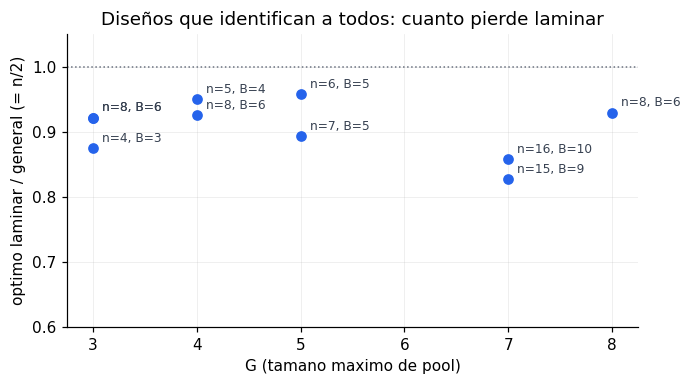

In [5]:
fig, ax = plt.subplots(figsize=(6.4, 3.6))
ax.scatter(tabla.G, tabla.razon, s=36, color=AZUL, zorder=3)
for _, r in tabla.iterrows():
    ax.annotate(f'n={r.n}, B={r.B}', (r.G, r.razon), textcoords='offset points', xytext=(6, 4), fontsize=8, color=TINTA)
ax.axhline(1, color=GRIS, ls=':', lw=1)
ax.set(xlabel='G (tamano maximo de pool)', ylabel='optimo laminar / general (= n/2)',
       title='Diseños que identifican a todos: cuanto pierde laminar', ylim=(0.6, 1.05))
plt.tight_layout(); plt.show()

Los diseños encontrados por búsqueda no son mínimos certificados; sirven como cota inferior del lado general. La razón baja de 0.875 en $n=4$ a 0.828 en $n=15$; con $n\le16$ son pocos puntos y no se extrapola.

Para discutir: ¿qué sucesión $(n,B,G)$ propone la construcción de Lindström, y con qué constante delante de $B\log_2 G$?

## 3. El lema de información, por la segunda vía

Una historia que despeja $m$ personas solo ocurre en mundos donde esas $m$ tienen su estado exacto: probabilidad a lo sumo $2^{-m}$. Juguete: un árbol con $K=9$ hojas no puede despejar más de $\log_2 9+1\approx4.17$ personas en promedio.

Afirmación: en 24 de las 32 celdas de la malla (las de $n=7$ con $G\ge4$ exceden el límite de estados del solver de perfiles), el árbol óptimo general cumple hoja por hoja $m(h)\le\log_2(1/P(h))$ y en promedio $\mathbb E[\text{despejados}]\le\log_2K+1\le B\log_2(G+1)+1$.

In [6]:
import csv
from augmented.bellman_perfiles import BellmanPerfiles

grid = list(csv.DictReader(open(os.path.join(os.path.dirname(os.path.dirname(os.path.abspath(''))),
                                          'results/precio_q05_G/malla_2026-10-14_completa.csv'))))
def leaves(node, prob=F(1)):
    if 'branches' not in node:
        yield prob, len(node['healthy']); return
    for b in node['branches']:
        yield from leaves(b['next'], prob * F(b['probability']))

lema, t0 = [], time.time()
for r in grid:
    n, B, G = int(r['n']), int(r['B']), int(r['G'])
    if n == 7 and G >= 4:
        continue  # el solver de perfiles sin simetria excede su limite de estados
    solver = BellmanPerfiles([F(1, 2)] * n, [F(1)] * n, G, laminar=False)
    value = solver.solve(B).value
    assert value == F(r['unrestricted'])
    hojas = list(leaves(solver.tree(B)))
    K = len(hojas)
    assert all(m <= log2(1 / p) + 1e-12 for p, m in hojas)
    esperado = sum(p * m for p, m in hojas)
    assert esperado == value and float(value) <= log2(K) + 1 and K <= (G + 1) ** B
    lema.append(dict(n=n, B=B, G=G, despejados=float(value), log2K=log2(K), K=K, cota=B * log2(G + 1)))
lema = pd.DataFrame(lema)
print(f'{len(lema)} celdas en {time.time()-t0:.0f} s; max despejados - log2 K = {(lema.despejados - lema.log2K).max():.3f} (cota 1)')
lema.sort_values(['n', 'B', 'G']).tail(6)

24 celdas en 14 s; max despejados - log2 K = -0.500 (cota 1)


,n,B,G,despejados,log2K,K,cota
17,7,2,2,1.25,2.584963,6,3.169925
21,7,2,3,1.25,2.584963,6,4.000000
18,7,3,2,2.00,4.169925,18,4.754888
22,7,3,3,2.25,4.700440,26,6.000000
19,7,4,2,2.75,5.754888,54,6.339850
23,7,4,3,3.25,6.584963,96,8.000000


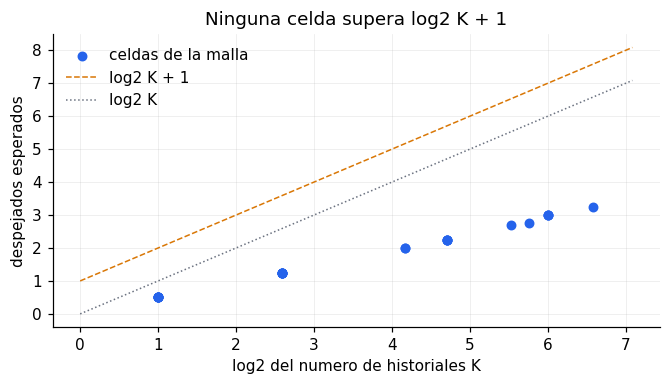

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.scatter(lema.log2K, lema.despejados, s=30, color=AZUL, zorder=3, label='celdas de la malla')
x = np.linspace(0, lema.log2K.max() + .5, 50)
ax.plot(x, x + 1, color=AMBAR, ls='--', lw=1, label='log2 K + 1')
ax.plot(x, x, color=GRIS, ls=':', lw=1, label='log2 K')
ax.set(xlabel='log2 del numero de historiales K', ylabel='despejados esperados',
       title='Ninguna celda supera log2 K + 1')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

El margen frente a $\log_2K+1$ nunca baja de una fracción de persona, y la cota $B\log_2(G+1)$ queda más lejos aún: los árboles óptimos usan muchos menos historiales que los $(G+1)^B$ posibles.

Para discutir: ¿el $+1$ del promedio se puede quitar con el argumento de Francisco, o es el precio de pasar de "siempre" a "en promedio"?

## 4. Barrido de la nota "individuales nunca óptimas"

La nota afirma que, con conteos y soft clearing, $B\ge2$, $G\ge2$, $n\ge B+1$, probar solo individuos nunca es óptimo laminar. Juguete: con $n=3$, $B=2$, $G=2$ y $q=0.3$, el par y un individuo pagan más que dos individuos.

Afirmación: el barrido con una semilla propia termina con `fails 0`. La firma es tuya: cambia `SEMILLA`, corre, y escribe la fila en la nota de encargos.

In [8]:
import subprocess
SEMILLA, SEGUNDOS = 20261026, 30
root = os.path.dirname(os.path.dirname(os.path.abspath('')))
out = subprocess.run([sys.executable, 'augmented/barrido_proposicion_individuales.py', str(SEMILLA), str(SEGUNDOS), '6', '4', '4'],
                     cwd=root, env=dict(os.environ, PYTHONPATH='.'), capture_output=True, text=True)
print(out.stdout[-600:] or out.stderr[-600:])
assert out.returncode == 0 and 'fails 0' in out.stdout, 'el barrido no cerro en cero fallas'
print('Los 934 tests: PYTHONPATH=. python -m pytest augmented/tests_brecha_convencion.py -q')

seed 20261026 counts {'boundary_n<=B': 545, 'interior': 741, 'boundary_B=1': 451} fails 0
min optimum/individual ratio in interior: 1.0000219674556212 at n,G,B = (3, 2, 2)

Los 934 tests: PYTHONPATH=. python -m pytest augmented/tests_brecha_convencion.py -q


Si el barrido cierra en cero y los 934 tests pasan, la firma es una fila en `docs/notes/2026-10-12-encargos-6-oct.md` con la semilla y la fecha. Si algo falla, la discrepancia es el resultado de la semana.

Para discutir: ¿basta esta nota como pieza base de A, o Francisco espera también los pasos 3 y 4?